# Fig 3 restructured (working copy)

Working notebook for the **Week 82** Figure 3 restructure so panels can be edited interactively.
Does **not** replace `vizpub/fig3.ipynb`.

- Source script: [`scripts/plot_fig3_restructured.py`](../scripts/plot_fig3_restructured.py)
- Style source of truth: [`vizpub/fig3.ipynb`](../vizpub/fig3.ipynb) (`FUNCTION_COLORS`, Arial/`fontsize=7`, cluster order sensory → sustain → motor, loaders/helpers)
- Style guide: [`docs/PLOTTING_STYLE.md`](../docs/PLOTTING_STYLE.md)
- SVG only. Run load / spatial / raster cells on a **compute node** in `ieeg` — not the login node.

## Current scientific scope (from the script)

| Panel | Epoch | Tasks / conditions | Window |
|-------|-------|--------------------|--------|
| **A** | schematic | Passive → Repeat → Decision | Stimulus / Delay / Response |
| **B INPUT** | stimulus | PictureNaming Repeat, sound vs image | (−0.5, 0.6) s |
| **C DELAY** | delay | LexicalDelay, Decision vs Repeat | (−0.05, 0.4) s |
| **D OUTPUT** | response | PictureNaming, Repeat vs Passive | (−0.05, 0.6) s |

Passive is loaded for PictureNaming only. LexicalNoDelay is **off** in this scope.
INPUT spatial reuses the existing SVG `img/fig3/fig3_pn_repeat_sound_vs_image_spatial.svg` (not re-rendered here).

## Open questions (SHI-93 checklist — not implemented)

These are review asks that the restructured script does **not** do. Decide before promoting:

1. **LexicalNoDelay Passive** — include LND Passive in the three-condition story / bars?
2. **Bar chart** — move condition bar summary to supplementary; main figure keeps anatomy?
3. **Bar color legend + order** — Repeat → Decision → Passive (script schematic is Passive → Repeat → Decision)?
4. **Sustain asterisks** — mark significant Sustain results on anatomy panels?

Edit the **Parameters** cell below to change task list, condition mapping, and epoch windows.


## Imports

Same stack as `vizpub/fig3.ipynb` (`fig3-imports`).


In [61]:
%matplotlib inline

import base64
import html
import os
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from IPython.display import display
from matplotlib.colors import to_hex, to_rgb
from matplotlib.lines import Line2D
from mne_bids import BIDSPath
from tqdm.auto import tqdm

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.connectivity.pairwise.config import DEFAULT_DATASETS
from src.nmf.waveform_analysis import CLUSTER_LABELS, FUNCTION_COLORS
from src.paths import hga_results_dir, img_dir, nmf_assignments_path, save_svg


## Style + parameters

House style from `vizpub/fig3.ipynb` (`fig3-style`): Arial, `fontsize=7`, `FUNCTION_COLORS`, `CLUSTERS`.

**Restructured scope** (narrower than full Fig 3): only LexicalDelay + PictureNaming; Passive only on PictureNaming.
Epoch windows and contrast levels are explicit so they are easy to edit.


In [62]:
from matplotlib import font_manager

for _ttf in (Path(sys.prefix) / "fonts").glob("arial*.ttf"):
    font_manager.fontManager.addfont(str(_ttf))

cm = 1 / 2.54
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]

fontsize = 7
fontdict = dict(fontsize=fontsize)

# Cluster display order for rasters / traces / spatial legends (sensory → sustain → motor).
CLUSTERS = ["sensory", "sustain", "motor"]
CLUSTER_ROW_LABELS = {
    "sensory": "sensory",
    "sustain": "sustained",
    "motor": "motor",
}

# --- Restructured Figure 3 scope (edit these) ---
TASKS = ["LexicalDelay", "PictureNaming"]
TASK_BIDS = {
    task: str(root)
    for task, root in DEFAULT_DATASETS.items()
    if task in TASKS
}
DESCRIPTIONS = ["Passive", "Repeat", "Decision"]
CONDITION_TASKS = {
    "Passive": ["PictureNaming"],
    "Repeat": ["LexicalDelay", "PictureNaming"],
    "Decision": ["LexicalDelay"],
}

# Schematic row order in panel A (SHI-93 may prefer Repeat → Decision → Passive for bars).
SCHEMATIC_ORDER = ("Passive", "Repeat", "Decision")

# Epoch panel specs: phase, compare field, levels, xlim, task, spatial contrast kwargs.
EPOCH_SPECS = {
    "input": {
        "phase": "stimulus",
        "compare_field": "modality",
        "levels": ("sound", "image"),
        "xlim": (-0.5, 0.6),
        "task": "PictureNaming",
        "heading": "INPUT",
        "subtitle": "Sound vs Image",
        "panel": "B",
    },
    "delay": {
        "phase": "delay",
        "compare_field": "description",
        "levels": ("Decision", "Repeat"),
        "xlim": (-0.05, 0.4),
        "ylim": (0.0, 0.3),
        "task": "LexicalDelay",
        "heading": "DELAY",
        "subtitle": "Decision vs Repeat",
        "panel": "C",
        "spatial_contrast": "DecisionVsRepeatMean",
        "spatial_phase": "Delay",
        "spatial_direction": "Decision",
    },
    "output": {
        "phase": "response",
        "compare_field": "description",
        "levels": ("Repeat", "Passive"),
        "xlim": (-0.05, 0.6),
        "ylim": (0.0, 0.5),
        "task": "PictureNaming",
        "heading": "OUTPUT",
        "subtitle": "Repeat vs Passive",
        "panel": "D",
        "spatial_contrast": "RepeatVsPassiveMean",
        "spatial_phase": "Response",
        "spatial_direction": "Repeat",
    },
}

REF = "bipolar"
BAND = "highgamma"
MODALITY = "sound"
HEMI = None
EXCLUDE_SUBJECTS = {"D0121"}
TIME_MAX = 1.5

# Outlier Passive-response electrodes (same set as vizpub/fig3.ipynb).
DROP_CHANNELS = {
    "D0125_LTMS3-4",
    "D0125_LTMS2-3",
    "D0125_LTMS1-2",
    "D0129_LFAI2-3",
}

NMF_ASSIGNMENTS = nmf_assignments_path()
IMG_DIR = img_dir("fig3")
PUB_DIR = img_dir("pub")
IMG_DIR.mkdir(parents=True, exist_ok=True)
PUB_DIR.mkdir(parents=True, exist_ok=True)

# Existing INPUT spatial SVG (script does not re-render this panel).
INPUT_SPATIAL_SVG = IMG_DIR / "fig3_pn_repeat_sound_vs_image_spatial.svg"

print("FUNCTION_COLORS:", FUNCTION_COLORS)
print("TASKS:", TASKS)
print("CONDITION_TASKS:", CONDITION_TASKS)
print("IMG_DIR:", IMG_DIR)


FUNCTION_COLORS: {'sustain': '#C4A35A', 'motor': '#A9373B', 'sensory': '#2369BD'}
TASKS: ['LexicalDelay', 'PictureNaming']
CONDITION_TASKS: {'Passive': ['PictureNaming'], 'Repeat': ['LexicalDelay', 'PictureNaming'], 'Decision': ['LexicalDelay']}
IMG_DIR: /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3


## Helpers

Ported from `vizpub/fig3.ipynb` (`fig3-helpers`): significance-union ∩ NMF assignments, trial-averaged z-score epochs.


In [63]:
def _norm_phase(phase: str) -> str:
    p = str(phase)
    if p == "Resp":
        p = "Response"
    elif p == "Audio":
        p = "Stimulus"
    return p.lower()


def _norm_subject(subject: str) -> str:
    return subject.removeprefix("sub-")


def _modality_of(path) -> str:
    return path.recording if path.recording is not None else "sound"


def epoch_root(bids_root: str) -> str:
    return str(Path(bids_root) / f"derivatives/epoch({REF})")


def load_assignments(path: Path | None = None) -> pd.DataFrame:
    path = Path(path) if path is not None else NMF_ASSIGNMENTS
    meta = pd.read_csv(path)
    required = {"subject", "channel", "functional_cluster"}
    missing = required - set(meta.columns)
    if missing:
        raise ValueError(f"{path} missing columns: {sorted(missing)}")
    meta = meta.copy()
    meta["subject"] = meta["subject"].map(_norm_subject)
    meta = meta[meta["functional_cluster"].isin(CLUSTERS)].copy()
    if HEMI is not None and "hemi" in meta.columns:
        meta = meta[meta["hemi"] == HEMI]
    meta = meta[~meta["subject"].isin(EXCLUDE_SUBJECTS)]
    meta = meta.drop_duplicates(subset=["subject", "channel"], keep="first")
    return meta.reset_index(drop=True)


def list_sig_paths(bids_root: str):
    return BIDSPath(
        root=epoch_root(bids_root),
        datatype="epoch(band)(sig)",
        suffix=BAND,
        extension=".h5",
        check=False,
    ).match()


def list_zscore_paths(bids_root: str):
    return BIDSPath(
        root=epoch_root(bids_root),
        datatype="epoch(band)(zscore)",
        suffix=BAND,
        extension=".h5",
        check=False,
    ).match()


def sig_union_by_subject(sig_paths, descriptions=DESCRIPTIONS) -> dict[str, set[str]]:
    by_subj: dict[str, set[str]] = defaultdict(set)
    for path in tqdm(sig_paths, desc="sig union"):
        if path.description not in descriptions:
            continue
        if _modality_of(path) != MODALITY:
            continue
        subj = _norm_subject(path.subject)
        if subj in EXCLUDE_SUBJECTS:
            continue
        epochs = mne.read_epochs(path, preload=False, verbose=False)
        by_subj[subj].update(epochs.ch_names)
    return dict(by_subj)


def evoked_to_long(epochs, channels: list[str]) -> pd.DataFrame | None:
    picks = [ch for ch in channels if ch in epochs.ch_names]
    if not picks:
        return None
    epo = epochs.copy().pick(picks)
    data = np.nanmean(epo.get_data(copy=False), axis=0)
    times = epo.times
    n_ch, n_t = data.shape
    return pd.DataFrame(
        {
            "time": np.tile(times, n_ch),
            "channel": np.repeat(list(epo.ch_names), n_t),
            "value": data.reshape(-1),
        }
    )


def load_task_waveforms(
    task: str,
    assignments: pd.DataFrame,
    *,
    descriptions=DESCRIPTIONS,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    bids_root = TASK_BIDS[task]
    sig_paths = list_sig_paths(bids_root)
    z_paths = list_zscore_paths(bids_root)
    if not sig_paths or not z_paths:
        raise FileNotFoundError(f"{task}: missing sig/zscore epochs under {bids_root}")

    unions = sig_union_by_subject(sig_paths, descriptions=descriptions)
    assign_by_subj = {
        subj: set(g["channel"]) for subj, g in assignments.groupby("subject")
    }
    channel_cluster = assignments.set_index(["subject", "channel"])[
        "functional_cluster"
    ].to_dict()
    channel_hemi = (
        assignments.set_index(["subject", "channel"])["hemi"].to_dict()
        if "hemi" in assignments.columns
        else {}
    )

    qc_rows = []
    restricted: dict[str, list[str]] = {}
    for subj, chans in unions.items():
        keep = sorted(chans & assign_by_subj.get(subj, set()))
        restricted[subj] = keep
        row = {
            "task": task,
            "subject": subj,
            "n_sig_union": len(chans),
            "n_functional_union": len(keep),
        }
        for cluster in CLUSTERS:
            row[f"n_{cluster}"] = sum(
                1 for ch in keep if channel_cluster.get((subj, ch)) == cluster
            )
        qc_rows.append(row)
    qc = pd.DataFrame(qc_rows)

    rows = []
    for path in tqdm(z_paths, desc=f"zscore {task}"):
        if path.description not in descriptions:
            continue
        if _modality_of(path) != MODALITY:
            continue
        subj = _norm_subject(path.subject)
        if subj in EXCLUDE_SUBJECTS:
            continue
        picks = restricted.get(subj)
        if not picks:
            continue
        epochs = mne.read_epochs(path, preload=True, verbose=False)
        df = evoked_to_long(epochs, picks)
        del epochs
        if df is None or df.empty:
            continue
        df["subject"] = subj
        df["description"] = path.description
        df["task"] = task
        df["phase"] = _norm_phase(path.processing)
        df["modality"] = _modality_of(path)
        df["functional_cluster"] = [
            channel_cluster.get((subj, ch)) for ch in df["channel"]
        ]
        df["hemi"] = [channel_hemi.get((subj, ch)) for ch in df["channel"]]
        rows.append(df)

    if not rows:
        return pd.DataFrame(), qc
    out = pd.concat(rows, ignore_index=True)
    out = out[
        out["functional_cluster"].isin(CLUSTERS) & (out["time"] < TIME_MAX)
    ].copy()
    out["cluster_label"] = out["functional_cluster"].map(CLUSTER_LABELS)
    return out, qc


def load_zscore_subset(
    task: str,
    assignments: pd.DataFrame,
    restricted: dict[str, list[str]],
    *,
    descriptions: list[str],
    phases: list[str],
) -> pd.DataFrame:
    # Read selected zscore epochs, reusing an existing electrode restriction.
    z_paths = list_zscore_paths(TASK_BIDS[task])
    phase_set = {_norm_phase(p) for p in phases}
    desc_set = set(descriptions)
    channel_cluster = assignments.set_index(["subject", "channel"])[
        "functional_cluster"
    ].to_dict()
    channel_hemi = (
        assignments.set_index(["subject", "channel"])["hemi"].to_dict()
        if "hemi" in assignments.columns
        else {}
    )
    rows = []
    label = f"zscore {task} {'/'.join(descriptions)} {'/'.join(phases)}"
    for path in tqdm(z_paths, desc=label):
        if path.description not in desc_set:
            continue
        if _norm_phase(path.processing) not in phase_set:
            continue
        if _modality_of(path) != MODALITY:
            continue
        subj = _norm_subject(path.subject)
        if subj in EXCLUDE_SUBJECTS:
            continue
        picks = restricted.get(subj)
        if not picks:
            continue
        epochs = mne.read_epochs(path, preload=True, verbose=False)
        df = evoked_to_long(epochs, picks)
        del epochs
        if df is None or df.empty:
            continue
        df["subject"] = subj
        df["description"] = path.description
        df["task"] = task
        df["phase"] = _norm_phase(path.processing)
        df["modality"] = _modality_of(path)
        df["functional_cluster"] = [
            channel_cluster.get((subj, ch)) for ch in df["channel"]
        ]
        df["hemi"] = [channel_hemi.get((subj, ch)) for ch in df["channel"]]
        rows.append(df)
    if not rows:
        return pd.DataFrame()
    out = pd.concat(rows, ignore_index=True)
    out = out[
        out["functional_cluster"].isin(CLUSTERS) & (out["time"] < TIME_MAX)
    ].copy()
    out["cluster_label"] = out["functional_cluster"].map(CLUSTER_LABELS)
    return out


## Load context waveforms

Heavy: reads `epoch(band)(sig)` then z-scored epochs for `TASKS` (LexicalDelay + PictureNaming).
PictureNaming Passive Response is spliced onto the existing PN electrode set (SHI-58), same as `fig3-load`.

Use a compute node in `ieeg`.


In [64]:
assignments = load_assignments()
print(
    f"NMF assignments: {len(assignments):,} | "
    f"subjects={assignments.subject.nunique()} | "
    + " | ".join(
        f"{CLUSTER_LABELS[c]}={int((assignments.functional_cluster == c).sum())}"
        for c in CLUSTERS
    )
)

hga_parts = []
for task in TASKS:
    print(f"\n=== {task} ===")
    part, _qc = load_task_waveforms(task, assignments)
    n_subj = part.subject.nunique() if len(part) else 0
    conds = sorted(part.description.unique()) if len(part) else []
    phases_present = sorted(part.phase.unique()) if len(part) else []
    print(
        f"  rows={len(part):,} | subjects={n_subj} | "
        f"conditions={conds} | phases={phases_present}"
    )
    if len(part):
        hga_parts.append(part)

working = pd.concat(hga_parts, ignore_index=True) if hga_parts else pd.DataFrame()

# SHI-58: splice PictureNaming Passive Response onto the existing electrode set.
pn = working[working["task"] == "PictureNaming"] if len(working) else pd.DataFrame()
if pn.empty:
    print("PictureNaming is not loaded — cannot append Passive Response.")
else:
    restricted = {
        subj: sorted(g["channel"].unique())
        for subj, g in pn.groupby("subject")
    }
    print(
        f"\n=== PictureNaming Passive response (append, "
        f"n_subjects={len(restricted)}) ==="
    )
    pn_resp = load_zscore_subset(
        "PictureNaming",
        assignments,
        restricted,
        descriptions=["Passive"],
        phases=["response"],
    )
    print(
        "  Passive response: "
        f"subjects={pn_resp.subject.nunique() if len(pn_resp) else 0} | "
        f"rows={len(pn_resp):,}"
    )
    drop = (
        (working["task"] == "PictureNaming")
        & (working["description"] == "Passive")
        & (working["phase"] == "response")
    )
    working = working.loc[~drop].copy()
    if len(pn_resp):
        working = pd.concat([working, pn_resp], ignore_index=True)

working = working.loc[~working["channel"].isin(DROP_CHANNELS)].copy()

for cond, tasks in CONDITION_TASKS.items():
    chunk = working[
        (working["description"] == cond) & (working["task"].isin(tasks))
    ]
    print(
        f"{cond}: tasks={sorted(chunk.task.unique()) if len(chunk) else []} | "
        f"subjects={chunk.subject.nunique() if len(chunk) else 0} | "
        f"rows={len(chunk):,}"
    )

print(
    f"\nworking rows={len(working):,} | "
    f"subjects={working.subject.nunique() if len(working) else 0}"
)


NMF assignments: 255 | subjects=63 | sensory=39 | sustained=83 | motor=133

=== LexicalDelay ===


sig union:   0%|          | 0/416 [00:00<?, ?it/s]

/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/858006484.py:69: RuntimeWarning: This filename (/cwork/ns458/BIDS-1.0_LexicalDecRepDelay/BIDS/derivatives/epoch(bipolar)/sub-D0023/epoch(band)(sig)/sub-D0023_proc-Delay_desc-Decision_highgamma.h5) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(path, preload=False, verbose=False)
/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/858006484.py:69: RuntimeWarning: This filename (/cwork/ns458/BIDS-1.0_LexicalDecRepDelay/BIDS/derivatives/epoch(bipolar)/sub-D0023/epoch(band)(sig)/sub-D0023_proc-Delay_desc-Repeat_highgamma.h5) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(path, preload=False, verbose=False)
/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/858006484.py:69: RuntimeWarning: This filename (/cwork/ns458/BI

zscore LexicalDelay:   0%|          | 0/416 [00:00<?, ?it/s]

/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/858006484.py:146: RuntimeWarning: This filename (/cwork/ns458/BIDS-1.0_LexicalDecRepDelay/BIDS/derivatives/epoch(bipolar)/sub-D0023/epoch(band)(zscore)/sub-D0023_task-LexicalDelay_proc-Delay_desc-Decision_highgamma.h5) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(path, preload=True, verbose=False)
/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/858006484.py:146: RuntimeWarning: This filename (/cwork/ns458/BIDS-1.0_LexicalDecRepDelay/BIDS/derivatives/epoch(bipolar)/sub-D0023/epoch(band)(zscore)/sub-D0023_task-LexicalDelay_proc-Delay_desc-Repeat_highgamma.h5) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(path, preload=True, verbose=False)
/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/858006484.py:146: Run

  rows=391,680 | subjects=38 | conditions=['Decision', 'Repeat'] | phases=['delay', 'go', 'response', 'stimulus']

=== PictureNaming ===


... (4 outputs left out)

  rows=289,280 | subjects=27 | conditions=['Passive', 'Repeat'] | phases=['delay', 'go', 'response', 'stimulus']

=== PictureNaming Passive response (append, n_subjects=27) ===


zscore PictureNaming Passive response:   0%|          | 0/888 [00:00<?, ?it/s]

/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/858006484.py:207: RuntimeWarning: This filename (/cwork/ns458/BIDS-1.3_PictureNaming/BIDS/derivatives/epoch(bipolar)/sub-D0079/epoch(band)(zscore)/sub-D0079_task-PictureNaming_proc-Response_recording-sound_desc-Passive_highgamma.h5) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(path, preload=True, verbose=False)
/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/858006484.py:207: RuntimeWarning: This filename (/cwork/ns458/BIDS-1.3_PictureNaming/BIDS/derivatives/epoch(bipolar)/sub-D0080/epoch(band)(zscore)/sub-D0080_task-PictureNaming_proc-Response_recording-sound_desc-Passive_highgamma.h5) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(path, preload=True, verbose=False)
/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel

  Passive response: subjects=27 | rows=36,160
Passive: tasks=['PictureNaming'] | subjects=27 | rows=139,520
Repeat: tasks=['LexicalDelay', 'PictureNaming'] | subjects=50 | rows=334,080
Decision: tasks=['LexicalDelay'] | subjects=38 | rows=194,560

working rows=668,160 | subjects=50


## Load Picture Naming Repeat (image + sound)

Same loader as `vizpub/fig3.ipynb` (`fig3-pn-load`). Needed for panel **B INPUT**.


In [65]:
PN_TASK = "PictureNaming"
PN_BIDS_ROOT = TASK_BIDS[PN_TASK]
TASK = PN_TASK
MODALITIES = ["sound", "image"]
PHASES = ["stimulus", "delay", "response"]
DISPLAY_LABELS = {cluster: CLUSTER_LABELS[cluster] for cluster in CLUSTERS}
BIDS_ROOT = PN_BIDS_ROOT


def load_picture_naming(assignments: pd.DataFrame) -> pd.DataFrame:
    """Trial-average PN Repeat zscore epochs for frozen NMF channels (image + sound)."""
    assign_by_subj = {
        subj: sorted(g["channel"]) for subj, g in assignments.groupby("subject")
    }
    clustered = assignments.set_index(["subject", "channel"])
    channel_cluster = clustered["functional_cluster"].to_dict()
    channel_roi = clustered["roi"].to_dict() if "roi" in clustered.columns else {}
    channel_hemi = clustered["hemi"].to_dict() if "hemi" in clustered.columns else {}
    xyz = {}
    if {"x", "y", "z"}.issubset(clustered.columns):
        xyz = clustered[["x", "y", "z"]].to_dict("index")

    desc_set = {"Repeat"}
    mod_set = set(MODALITIES)
    phase_set = set(PHASES)
    rows = []
    n_empty = 0
    for path in tqdm(list_zscore_paths(BIDS_ROOT), desc="PN Repeat zscore"):
        if path.description not in desc_set:
            continue
        modality = _modality_of(path)
        if modality not in mod_set:
            continue
        phase = _norm_phase(path.processing)
        if phase not in phase_set:
            continue
        subj = _norm_subject(path.subject)
        if subj in EXCLUDE_SUBJECTS:
            continue
        picks = assign_by_subj.get(subj)
        if not picks:
            continue
        epochs = mne.read_epochs(path, preload=True, verbose=False)
        df = evoked_to_long(epochs, picks)
        del epochs
        if df is None or df.empty:
            n_empty += 1
            continue
        df["subject"] = subj
        df["description"] = path.description
        df["task"] = TASK
        df["phase"] = phase
        df["modality"] = modality
        keys = list(zip([subj] * len(df), df["channel"]))
        df["functional_cluster"] = [channel_cluster.get(k) for k in keys]
        df["roi"] = [channel_roi.get(k) for k in keys]
        df["hemi"] = [channel_hemi.get(k) for k in keys]
        if xyz:
            df["x"] = [xyz[k]["x"] if k in xyz else np.nan for k in keys]
            df["y"] = [xyz[k]["y"] if k in xyz else np.nan for k in keys]
            df["z"] = [xyz[k]["z"] if k in xyz else np.nan for k in keys]
        rows.append(df)

    if not rows:
        raise FileNotFoundError(f"No PN zscore rows for NMF channels under {BIDS_ROOT}")
    out = pd.concat(rows, ignore_index=True)
    out = out[out["functional_cluster"].isin(CLUSTERS) & (out["time"] < TIME_MAX)].copy()
    out["cluster_label"] = out["functional_cluster"].map(DISPLAY_LABELS)
    print("empty pick files:", n_empty)
    return out


pn_repeat = load_picture_naming(assignments)
repeat = pn_repeat.copy()
print(
    "PN Repeat rows",
    len(repeat),
    "| channels",
    repeat.channel.nunique(),
    "| subjects",
    repeat.subject.nunique(),
    "| modalities",
    sorted(repeat.modality.unique()),
    "| phases",
    sorted(repeat.phase.unique()),
)
cov = (
    repeat.groupby(["functional_cluster", "modality"])["channel"]
    .nunique()
    .unstack("modality")
    .reindex(index=CLUSTERS, columns=MODALITIES)
)
print("Repeat unique channels by cluster × modality")
display(cov)


PN Repeat zscore:   0%|          | 0/888 [00:00<?, ?it/s]

/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/1840527500.py:43: RuntimeWarning: This filename (/cwork/ns458/BIDS-1.3_PictureNaming/BIDS/derivatives/epoch(bipolar)/sub-D0079/epoch(band)(zscore)/sub-D0079_task-PictureNaming_proc-Delay_recording-image_desc-Repeat_highgamma.h5) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(path, preload=True, verbose=False)
/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009/1840527500.py:43: RuntimeWarning: This filename (/cwork/ns458/BIDS-1.3_PictureNaming/BIDS/derivatives/epoch(bipolar)/sub-D0079/epoch(band)(zscore)/sub-D0079_task-PictureNaming_proc-Delay_recording-sound_desc-Repeat_highgamma.h5) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(path, preload=True, verbose=False)
/hpc/home/ns458/coganlab/nanlinshi/tmp/ipykernel_3860009

empty pick files: 0
PN Repeat rows 255360 | channels 133 | subjects 27 | modalities ['image', 'sound'] | phases ['delay', 'response', 'stimulus']
Repeat unique channels by cluster × modality


modality,sound,image
functional_cluster,,
sensory,19,19
sustain,52,52
motor,62,62


## Epoch plot helpers + packaged masks

Raster / mean±SEM traces / contrast spatial from `scripts/plot_fig3_restructured.py`, using `FUNCTION_COLORS` and `CLUSTERS` from Fig 3 style.
Spatial contrast rendering reuses `src.univariate.viz_mean` + `render_insula_hemisphere_cluster` (same stack as the script).


In [66]:
def add_packaged_mask(
    df: pd.DataFrame,
    *,
    task: str,
) -> pd.DataFrame:
    """Attach the packaged time-resolved significance mask to HGA traces."""
    if df.empty:
        return df.assign(mask=False)

    wanted_subjects = set(df["subject"].astype(str).str.removeprefix("sub-"))
    wanted_descriptions = set(df["description"].astype(str))
    wanted_modalities = set(df["modality"].astype(str))
    wanted_phases = set(df["phase"].astype(str).str.lower())
    paths = BIDSPath(
        root=str(hga_results_dir(task)),
        datatype="HGA",
        suffix="time",
        check=False,
    ).match()

    frames: list[pd.DataFrame] = []
    for path in paths:
        subject = str(path.subject).removeprefix("sub-")
        description = str(path.description)
        modality = path.recording if path.recording is not None else "sound"
        phase = str(path.processing).lower()
        if phase == "resp":
            phase = "response"
        elif phase == "audio":
            phase = "stimulus"
        if (
            subject not in wanted_subjects
            or description not in wanted_descriptions
            or modality not in wanted_modalities
            or phase not in wanted_phases
        ):
            continue
        frame = pd.read_csv(
            path,
            usecols=[
                "channel",
                "time",
                "mask",
                "subject",
                "phase",
                "modality",
                "description",
            ],
        )
        if frame.empty:
            continue
        frame["subject"] = frame["subject"].astype(str).str.removeprefix("sub-")
        frame["phase"] = frame["phase"].astype(str).str.lower().replace(
            {"resp": "response", "audio": "stimulus"}
        )
        frame["time"] = np.round(frame["time"].to_numpy(dtype=float), 4)
        frames.append(frame)

    out = df.drop(columns=["mask"], errors="ignore").copy()
    out["subject"] = out["subject"].astype(str).str.removeprefix("sub-")
    out["time"] = np.round(out["time"].to_numpy(dtype=float), 4)
    if not frames:
        print(f"WARNING: no packaged masks found for {task}; showing raw HGA")
        out["mask"] = True
        return out

    mask_df = pd.concat(frames, ignore_index=True).drop_duplicates(
        subset=[
            "subject",
            "channel",
            "time",
            "phase",
            "modality",
            "description",
        ],
        keep="first",
    )
    out = out.merge(
        mask_df,
        on=[
            "subject",
            "channel",
            "time",
            "phase",
            "modality",
            "description",
        ],
        how="left",
    )
    out["mask"] = out["mask"].fillna(False).astype(bool)
    print(
        f"{task}: mask fraction={out['mask'].mean():.3f}; "
        f"significant electrodes={out.loc[out['mask'], 'channel'].nunique()}"
    )
    return out


def _electrode_key(df: pd.DataFrame) -> pd.Series:
    return df["subject"].astype(str) + "|" + df["channel"].astype(str)


def plot_epoch_raster(
    df: pd.DataFrame,
    *,
    phase: str,
    compare_field: str,
    levels: tuple[str, str],
    xlim: tuple[float, float],
    colors: dict[str, str] | None = None,
    out_path: Path | None = None,
):
    """Three cluster rows; two conditions stacked within each row."""
    colors = colors or FUNCTION_COLORS
    clusters = tuple(CLUSTERS)
    labels = CLUSTER_ROW_LABELS
    sub = df.loc[
        (df["phase"] == phase)
        & df[compare_field].isin(levels)
        & df["functional_cluster"].isin(clusters)
        & df["time"].between(*xlim)
    ].copy()
    sub["electrode"] = _electrode_key(sub)
    sub.loc[~sub["mask"], "value"] = np.nan

    # Match vizpub/fig3.ipynb context-trace panel height (6.5 cm) and
    # single-column width from the difference-waveform formula (2.2+1.0 cm).
    fig, axes = plt.subplots(3, 1, figsize=(3.2 * cm, 6.5 * cm), sharex=True)
    for ax, cluster in zip(axes, clusters):
        chunk = sub.loc[sub["functional_cluster"] == cluster].copy()
        any_sig = chunk.groupby("electrode")["mask"].any()
        electrodes = any_sig.index[any_sig].tolist()
        if electrodes:
            peak = (
                chunk.loc[chunk["electrode"].isin(electrodes) & chunk["mask"]]
                .groupby("electrode")["time"]
                .min()
                .sort_values()
            )
            electrodes = peak.index.tolist()

        pivots = []
        all_times = sorted(chunk["time"].dropna().unique())
        for level in reversed(levels):
            pivot = (
                chunk.loc[chunk[compare_field] == level]
                .pivot_table(
                    index="electrode", columns="time", values="value", aggfunc="mean"
                )
                .reindex(index=electrodes, columns=all_times)
            )
            pivots.append(pivot)

        matrix = pd.concat(pivots, axis=0).to_numpy(dtype=float)
        positive = matrix[np.isfinite(matrix) & (matrix > 0)]
        vmax = max(float(np.quantile(positive, 0.95)), 0.15) if positive.size else 1.0
        cmap = sns.light_palette(colors[cluster], as_cmap=True)
        cmap.set_bad("white")
        if matrix.size:
            ax.imshow(
                matrix,
                extent=(xlim[0], xlim[1], 0, max(matrix.shape[0], 1)),
                aspect="auto",
                origin="lower",
                cmap=cmap,
                vmin=0,
                vmax=vmax,
                interpolation="nearest",
                rasterized=True,
            )
        n = len(electrodes)
        ax.axhline(n, color="0.25", ls="--", lw=0.8)
        ax.axvline(0, color="0.2", ls="--", lw=0.8)
        ax.set_xlim(*xlim)
        ax.set_yticks([])
        ax.set_ylabel(labels[cluster], color=colors[cluster], fontsize=fontsize)
        if n:
            ax.text(0.02, 0.75, levels[0], transform=ax.transAxes, fontsize=fontsize)
            ax.text(0.02, 0.25, levels[1], transform=ax.transAxes, fontsize=fontsize)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(labelsize=fontsize, width=0.75, length=2, which="both")
    axes[-1].set_xlabel("Time (s)", fontsize=fontsize)
    axes[-1].set_xticks([xlim[0], 0, xlim[1]])
    fig.tight_layout(h_pad=0.6)
    if out_path is not None:
        out_path = Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_path, format="svg", bbox_inches="tight")
        print("wrote", out_path)
    return fig, axes


def plot_epoch_traces(
    df: pd.DataFrame,
    *,
    phase: str,
    compare_field: str,
    levels: tuple[str, str],
    xlim: tuple[float, float],
    ylim: tuple[float, float] | None = None,
    colors: dict[str, str] | None = None,
    out_path: Path | None = None,
):
    colors = colors or FUNCTION_COLORS
    clusters = tuple(CLUSTERS)
    labels = CLUSTER_ROW_LABELS
    sub = df.loc[
        (df["phase"] == phase)
        & df[compare_field].isin(levels)
        & df["functional_cluster"].isin(clusters)
        & df["time"].between(*xlim)
    ].copy()
    sub["electrode"] = _electrode_key(sub)

    # Same house size as raster / one column of fig3 context traces.
    fig, axes = plt.subplots(3, 1, figsize=(3.2 * cm, 6.5 * cm), sharex=True)
    for ax, cluster in zip(axes, clusters):
        chunk = sub.loc[sub["functional_cluster"] == cluster]
        for idx, level in enumerate(levels):
            level_df = chunk.loc[chunk[compare_field] == level]
            electrode_mean = (
                level_df.groupby(["electrode", "time"], as_index=False)["value"].mean()
            )
            summary = electrode_mean.groupby("time")["value"].agg(["mean", "sem"])
            if summary.empty:
                continue
            line_color = colors[cluster] if idx == 0 else "#333333"
            linestyle = "-" if idx == 0 else "--"
            ax.plot(
                summary.index,
                summary["mean"],
                color=line_color,
                ls=linestyle,
                lw=1.0,
                label=level,
            )
            ax.fill_between(
                summary.index,
                summary["mean"] - summary["sem"],
                summary["mean"] + summary["sem"],
                color=line_color,
                alpha=0.18,
                linewidth=0,
            )
        ax.axhline(0, color="0.2", ls="--", lw=0.7)
        ax.axvline(0, color="0.2", ls="--", lw=0.7)
        ax.set_xlim(*xlim)
        if ylim is not None:
            ax.set_ylim(*ylim)
        ax.set_ylabel(labels[cluster], color=colors[cluster], fontsize=fontsize)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=fontsize, width=0.75, length=2, which="both")
    handles = [
        Line2D([0], [0], color="black", lw=1.0, ls="-", label=levels[0]),
        Line2D([0], [0], color="black", lw=1.0, ls="--", label=levels[1]),
    ]
    axes[0].legend(handles=handles, loc="upper right", frameon=False, fontsize=fontsize)
    axes[-1].set_xlabel("Time (s)", fontsize=fontsize)
    axes[-1].set_xticks([xlim[0], 0, xlim[1]])
    fig.tight_layout(h_pad=0.55)
    if out_path is not None:
        out_path = Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_path, format="svg", bbox_inches="tight")
        print("wrote", out_path)
    return fig, axes


def _crop_insula_screenshot(img, pad: int = 24):
    """Crop white margins so the insula fills the axis (fig3 crop_to_content)."""
    rgb = np.asarray(img)
    mask = np.any(rgb < 250, axis=2)
    if not mask.any():
        return rgb
    ys, xs = np.nonzero(mask)
    y0 = max(0, int(ys.min()) - pad)
    y1 = min(rgb.shape[0], int(ys.max()) + 1 + pad)
    x0 = max(0, int(xs.min()) - pad)
    x1 = min(rgb.shape[1], int(xs.max()) + 1 + pad)
    return rgb[y0:y1, x0:x1]


def plot_contrast_spatial(
    assignments: pd.DataFrame,
    *,
    task: str,
    phase: str,
    contrast: str,
    direction: str,
    out_path: Path | None = None,
):
    """Render significant insula electrodes for one epoch contrast.

    Matches vizpub/fig3.ipynb Decision>Repeat spatial panel recipe:
    - figsize (6.5*cm, 3.0*cm), LH|RH side-by-side
    - electrode point_size 16 (fig3 POINT_SIZE; not viz_insula_patterns SIG_SIZE=40)
    - crop_to_content so brains fill axes
    - left legend + subplots_adjust(left=0.28, ...)
    - save_svg (dpi=300, bbox_inches='tight')
    """
    from src.decoding.viz_insula_patterns import render_insula_hemisphere_cluster
    from src.univariate.viz_mean import (
        BrainSurfaceContext,
        attach_metadata,
        filter_insula_electrodes,
        filter_qc,
        load_coord_metadata,
        load_mean_contrasts,
        resolve_mean_results_root,
        select_significant,
    )

    root = resolve_mean_results_root(task=task, contrast_desc=contrast)
    table = load_mean_contrasts(
        root, tasks=(task,), phase=phase, contrast_desc=contrast
    )
    coords = load_coord_metadata(root, tasks=(task,))
    table = filter_insula_electrodes(filter_qc(attach_metadata(table, coords)))
    table = select_significant(
        table, phase=phase, contrast=contrast, tasks=(task,)
    )
    table = table.loc[table["direction"] == direction].copy()
    table = table.merge(
        assignments[["channel", "functional_cluster"]].drop_duplicates("channel"),
        on="channel",
        how="inner",
    )
    table["pattern"] = table["mean_diff"].abs().astype(float)
    table["significant"] = True

    context = BrainSurfaceContext()
    # fig3 recipe: one wide figure, two small LH/RH axes (not separate figures).
    fig, axes = plt.subplots(1, 2, figsize=(6.5 * cm, 3.0 * cm))
    for ax, (hemi, label) in zip(axes, (("lh", "Left"), ("rh", "Right"))):
        # size_range=(16,16) forces fig3 POINT_SIZE; size_by_pattern=False
        # would use SIG_SIZE=40 from viz_insula_patterns (too large).
        # cluster_colors=FUNCTION_COLORS: house palette (not CLUSTER_COLORS swap).
        image = render_insula_hemisphere_cluster(
            table,
            hemi,
            context,
            size_by_pattern=True,
            size_range=(16.0, 16.0),
            cluster_colors=FUNCTION_COLORS,
        )
        image = _crop_insula_screenshot(image, pad=24)
        ax.imshow(image)
        ax.set_xlim(0, image.shape[1])
        ax.set_ylim(image.shape[0], 0)
        ax.axis("off")
        ax.set_title(label, fontsize=fontsize)

    n_by_cluster = table.groupby("functional_cluster")["channel"].nunique()
    axes[0].legend(
        handles=[
            Line2D(
                [0],
                [0],
                color=FUNCTION_COLORS[c],
                linewidth=0.9,
                label=f"{CLUSTER_LABELS.get(c, c)}  (n={int(n_by_cluster.get(c, 0))})",
            )
            for c in CLUSTERS
        ],
        frameon=False,
        fontsize=fontsize,
        loc="upper right",
        bbox_to_anchor=(-0.04, 1.0),
        borderaxespad=0.0,
    )
    fig.subplots_adjust(wspace=0.02, left=0.28, right=0.98, top=0.92, bottom=0.02)
    if out_path is not None:
        out = save_svg(fig, Path(out_path))
        print("wrote", out)
    return fig, axes


## Panel A — task schematic

Hardcoded Passive → Repeat → Decision × Stimulus–Delay–Response (same as the script).
Open question: SHI-93 bar order is Repeat → Decision → Passive — change `SCHEMATIC_ORDER` if needed.


In [67]:
def task_schematic(order=SCHEMATIC_ORDER) -> str:
    info = {
        "Passive": ("Sound", "No response", "#333333"),
        "Repeat": ("Sound or image", "Spoken response", "#333333"),
        "Decision": ("Sound", "Yes / No", "#333333"),
    }
    parts = [
        '<text x="96" y="118" class="panel">A</text>',
        '<text x="190" y="118" class="section">Task structure</text>',
        '<text x="680" y="118" class="event">Stimulus</text>',
        '<text x="1510" y="118" class="event">Delay</text>',
        '<text x="2370" y="118" class="event">Response</text>',
    ]
    for idx, name in enumerate(order):
        stimulus, response, color = info[name]
        y = 168 + idx * 70
        parts.extend(
            [
                f'<text x="225" y="{y + 12}" class="condition" fill="{color}">{html.escape(name)}</text>',
                f'<line x1="610" y1="{y}" x2="3000" y2="{y}" stroke="#333" stroke-width="3"/>',
                f'<circle cx="780" cy="{y}" r="8" fill="{color}"/>',
                f'<circle cx="1640" cy="{y}" r="8" fill="{color}"/>',
                f'<circle cx="2500" cy="{y}" r="8" fill="{color}"/>',
                f'<text x="840" y="{y - 14}" class="small">{html.escape(stimulus)}</text>',
                f'<text x="1700" y="{y - 14}" class="small">Maintain task goal</text>',
                f'<text x="2560" y="{y - 14}" class="small">{html.escape(response)}</text>',
            ]
        )
    return "\n".join(parts)


print("Schematic order:", SCHEMATIC_ORDER)
print(task_schematic()[:200], "...")


Schematic order: ('Passive', 'Repeat', 'Decision')
<text x="96" y="118" class="panel">A</text>
<text x="190" y="118" class="section">Task structure</text>
<text x="680" y="118" class="event">Stimulus</text>
<text x="1510" y="118" class="event">Delay</ ...


## Build epoch dataframes (B / C / D)

Slice `pn_repeat` / `working` to the three epoch contrasts and attach packaged significance masks.


In [68]:
input_df = pn_repeat.loc[
    (pn_repeat["phase"] == "stimulus")
    & pn_repeat["modality"].isin(["sound", "image"])
].copy()
delay_df = working.loc[
    (working["task"] == "LexicalDelay")
    & (working["phase"] == "delay")
    & working["description"].isin(["Decision", "Repeat"])
].copy()
output_df = working.loc[
    (working["task"] == "PictureNaming")
    & (working["phase"] == "response")
    & working["description"].isin(["Repeat", "Passive"])
].copy()

input_df = add_packaged_mask(input_df, task="PictureNaming")
delay_df = add_packaged_mask(delay_df, task="LexicalDelay")
output_df = add_packaged_mask(output_df, task="PictureNaming")

for name, df in (("input", input_df), ("delay", delay_df), ("output", output_df)):
    print(
        f"{name}: rows={len(df):,} | "
        f"subjects={df.subject.nunique() if len(df) else 0} | "
        f"channels={df.channel.nunique() if len(df) else 0}"
    )


PictureNaming: mask fraction=0.069; significant electrodes=75
LexicalDelay: mask fraction=0.186; significant electrodes=115
PictureNaming: mask fraction=0.095; significant electrodes=75
input: rows=85,120 | subjects=27 | channels=133
delay: rows=97,280 | subjects=38 | channels=152
output: rows=69,760 | subjects=27 | channels=109


## Panel B — INPUT (Sound vs Image)

PictureNaming Repeat, stimulus window (−0.5, 0.6) s.

1. **Spatial** — reuse published `fig3_pn_repeat_sound_vs_image_spatial.svg`.
   That panel is a **2×2** fig3 recipe (sound-preferential / image-preferential rows),
   not the 1×2 mean-contrast layout used by delay/output via `plot_contrast_spatial`.
   Preferential-set data for redrawing is not loaded in this notebook.
2. **Raster** — cluster rows, sound / image stacked.
3. **Traces** — mean ± SEM.


INPUT spatial exists: True /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3/fig3_pn_repeat_sound_vs_image_spatial.svg
wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3/fig3_epoch_input_raster.svg


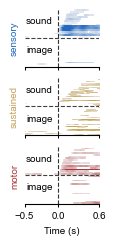

wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3/fig3_epoch_input_traces.svg


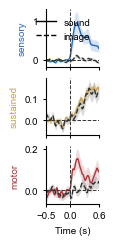

In [69]:
spec = EPOCH_SPECS["input"]
paths_input = {
    "spatial": INPUT_SPATIAL_SVG,
    "raster": IMG_DIR / "fig3_epoch_input_raster.svg",
    "traces": IMG_DIR / "fig3_epoch_input_traces.svg",
}

print("INPUT spatial exists:", paths_input["spatial"].exists(), paths_input["spatial"])

fig_r, _ = plot_epoch_raster(
    input_df,
    phase=spec["phase"],
    compare_field=spec["compare_field"],
    levels=spec["levels"],
    xlim=spec["xlim"],
    colors=FUNCTION_COLORS,
    out_path=paths_input["raster"],
)
plt.show()

fig_t, _ = plot_epoch_traces(
    input_df,
    phase=spec["phase"],
    compare_field=spec["compare_field"],
    levels=spec["levels"],
    xlim=spec["xlim"],
    colors=FUNCTION_COLORS,
    out_path=paths_input["traces"],
)
plt.show()


## Panel C — DELAY (Decision vs Repeat)

LexicalDelay delay window (−0.05, 0.4) s. Spatial via `DecisionVsRepeatMean`, direction Decision.


Reading labels from parcellation...
   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot
   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 88: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 88: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card8: Permission denied

2026-09-26 19:32:32.707 (12067.147s) [    7FB2D6925740] vtkEGLRenderWindow.cxx:353   WARN| vtkEGLRenderWindow (0x6b8c030): EGL device index: 0 could not be initialized. Trying other devices...
libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 88: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 88: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/c

wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3/fig3_delay_decision_gt_repeat_spatial.svg


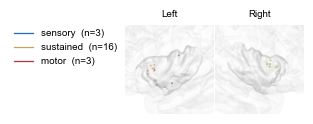

wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3/fig3_epoch_delay_raster.svg


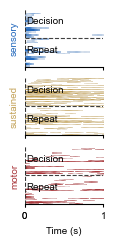

wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3/fig3_epoch_delay_traces.svg


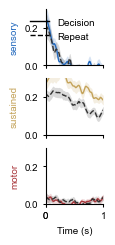

In [70]:
spec = EPOCH_SPECS["delay"]
paths_delay = {
    "spatial": IMG_DIR / "fig3_delay_decision_gt_repeat_spatial.svg",
    "raster": IMG_DIR / "fig3_epoch_delay_raster.svg",
    "traces": IMG_DIR / "fig3_epoch_delay_traces.svg",
}

os.environ.setdefault("PYVISTA_OFF_SCREEN", "true")
os.environ.setdefault("PYVISTA_USE_PANEL", "false")
os.environ.setdefault("MNE_3D_BACKEND", "notebook")

fig_s, _ = plot_contrast_spatial(
    assignments,
    task=spec["task"],
    phase=spec["spatial_phase"],
    contrast=spec["spatial_contrast"],
    direction=spec["spatial_direction"],
    out_path=paths_delay["spatial"],
)
plt.show()

fig_r, _ = plot_epoch_raster(
    delay_df,
    phase=spec["phase"],
    compare_field=spec["compare_field"],
    levels=spec["levels"],
    xlim=spec["xlim"],
    colors=FUNCTION_COLORS,
    out_path=paths_delay["raster"],
)
plt.show()

fig_t, _ = plot_epoch_traces(
    delay_df,
    phase=spec["phase"],
    compare_field=spec["compare_field"],
    levels=spec["levels"],
    xlim=spec["xlim"],
    ylim=spec["ylim"],
    colors=FUNCTION_COLORS,
    out_path=paths_delay["traces"],
)
plt.show()


## Panel D — OUTPUT (Repeat vs Passive)

PictureNaming response window (−0.05, 0.6) s. Spatial via `RepeatVsPassiveMean`, direction Repeat.


Reading labels from parcellation...
   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot
   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot


libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 88: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 88: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card8: Permission denied

2026-09-26 19:33:33.783 (12128.223s) [    7FB2D6925740] vtkEGLRenderWindow.cxx:353   WARN| vtkEGLRenderWindow (0x114553e0): EGL device index: 0 could not be initialized. Trying other devices...
libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 88: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: pci id for fd 87: 10de:26b2, driver (null)

pci id for fd 88: 10de:26b2, driver (null)
kmsro: driver missing
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/

wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3/fig3_output_repeat_gt_passive_spatial.svg


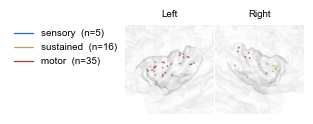

wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3/fig3_epoch_output_raster.svg


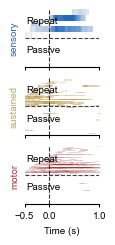

wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/fig3/fig3_epoch_output_traces.svg


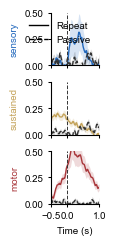

In [71]:
spec = EPOCH_SPECS["output"]
paths_output = {
    "spatial": IMG_DIR / "fig3_output_repeat_gt_passive_spatial.svg",
    "raster": IMG_DIR / "fig3_epoch_output_raster.svg",
    "traces": IMG_DIR / "fig3_epoch_output_traces.svg",
}

fig_s, _ = plot_contrast_spatial(
    assignments,
    task=spec["task"],
    phase=spec["spatial_phase"],
    contrast=spec["spatial_contrast"],
    direction=spec["spatial_direction"],
    out_path=paths_output["spatial"],
)
plt.show()

fig_r, _ = plot_epoch_raster(
    output_df,
    phase=spec["phase"],
    compare_field=spec["compare_field"],
    levels=spec["levels"],
    xlim=spec["xlim"],
    colors=FUNCTION_COLORS,
    out_path=paths_output["raster"],
)
plt.show()

fig_t, _ = plot_epoch_traces(
    output_df,
    phase=spec["phase"],
    compare_field=spec["compare_field"],
    levels=spec["levels"],
    xlim=spec["xlim"],
    ylim=spec["ylim"],
    colors=FUNCTION_COLORS,
    out_path=paths_output["traces"],
)
plt.show()


## Assemble master SVG (optional)

Writes `img/pub/pub-new_fig3-restructured.svg` from the nine panel SVGs (same layout as the script).
Requires all panel files to exist, including the pre-existing INPUT spatial SVG.


In [72]:
def svg_data_uri(path: Path) -> str:
    payload = base64.b64encode(path.read_bytes()).decode("ascii")
    return f"data:image/svg+xml;base64,{payload}"


def image_tag(path: Path, x: int, y: int, width: int, height: int) -> str:
    return (
        f'<image x="{x}" y="{y}" width="{width}" height="{height}" '
        f'preserveAspectRatio="xMidYMid meet" href="{svg_data_uri(path)}"/>'
    )


def assemble_master(panel_paths: dict[str, Path], out_path: Path) -> None:
    columns = (
        ("B", "INPUT", "Sound vs Image", 80, "input"),
        ("C", "DELAY", "Decision vs Repeat", 1240, "delay"),
        ("D", "OUTPUT", "Repeat vs Passive", 2400, "output"),
    )
    parts = [
        '<svg xmlns="http://www.w3.org/2000/svg" width="3600" height="2750" viewBox="0 0 3600 2750">',
        '<rect width="3600" height="2750" fill="white"/>',
        """<style>
        text { font-family: Arial, Helvetica, sans-serif; fill: #111; }
        .title { font-size: 58px; font-weight: 500; }
        .panel { font-size: 48px; font-weight: 700; }
        .section { font-size: 42px; font-weight: 700; }
        .subtitle { font-size: 32px; }
        .event { font-size: 30px; font-weight: 600; }
        .condition { font-size: 27px; font-weight: 600; }
        .small { font-size: 23px; }
        .rowlabel { font-size: 25px; fill: #555; }
        </style>""",
        '<text x="80" y="68" class="title">Fig. 3 | Insular dynamics dissociate input modality, upcoming goal, and speech output</text>',
        task_schematic(),
        '<line x1="80" y1="390" x2="3520" y2="390" stroke="#D0D0D0" stroke-width="3"/>',
    ]

    for panel, heading, subtitle, x, key in columns:
        parts.extend(
            [
                f'<text x="{x}" y="460" class="panel">{panel}</text>',
                f'<text x="{x + 90}" y="460" class="section">{heading}</text>',
                f'<text x="{x + 90}" y="505" class="subtitle">{subtitle}</text>',
                f'<text x="{x}" y="600" class="rowlabel">Spatial distribution</text>',
                image_tag(panel_paths[f"{key}_spatial"], x, 610, 1080, 560),
                f'<text x="{x}" y="1220" class="rowlabel">Electrode × time</text>',
                image_tag(panel_paths[f"{key}_raster"], x, 1230, 1080, 700),
                f'<text x="{x}" y="1990" class="rowlabel">Mean HGA</text>',
                image_tag(panel_paths[f"{key}_traces"], x, 2000, 1080, 690),
            ]
        )
    parts.append("</svg>")
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    out_path.write_text("\n".join(parts))
    print("wrote", out_path)


panel_paths = {
    "input_spatial": paths_input["spatial"],
    "delay_spatial": paths_delay["spatial"],
    "output_spatial": paths_output["spatial"],
    "input_raster": paths_input["raster"],
    "delay_raster": paths_delay["raster"],
    "output_raster": paths_output["raster"],
    "input_traces": paths_input["traces"],
    "delay_traces": paths_delay["traces"],
    "output_traces": paths_output["traces"],
}

missing = [str(p) for p in panel_paths.values() if not p.exists()]
if missing:
    print("Missing panels (run B/C/D cells first):")
    for m in missing:
        print(" ", m)
else:
    master = PUB_DIR / "pub-new_fig3-restructured.svg"
    assemble_master(panel_paths, master)


wrote /hpc/group/coganlab/nanlinshi/insula-functional/img/pub/pub-new_fig3-restructured.svg
